## multiple linear regression 

In [ ]:
# What Are You Predicting? The goal of this competition is to predict how long it takes a student to debug their code based on their experience, the complexity of the code, and their environment.

Modeling Notes This is a linear regression problem. Programming Language is a categorical variable and will need to be encoded before use in your model (e.g., one-hot encoding). Not all features are guaranteed to be useful, part of the challenge is identifying which ones actually drive debug time and which ones are just noise.

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt  

In [9]:
df= pd.read_csv("train.csv")

df.head(10)

,Bug ID,Programming Language,Years of Experience,Lines of Code,Hours Since Break,Number of Errors,Checked Stack Overflow,Time of Day,Caffeine Drinks,Hours Slept,Room Temp (F),Wearing Headphones,Debug Time (mins)
0,1,C++,4.0,705,2.5,4,0,18,4,9.8,75,1,85.7
1,2,Python,2.9,177,4.7,1,0,22,3,3.1,71,1,36.7
2,3,R,5.0,273,3.7,3,1,6,3,7.2,75,0,43.5
3,4,R,0.2,117,0.8,6,0,15,1,3.6,81,1,71.7
4,5,Java,4.8,253,0.3,9,1,1,3,5.6,82,1,63.9
5,6,Python,3.4,172,2.9,3,1,23,3,8.5,83,0,32.9
6,7,Java,1.8,248,2.9,7,0,6,1,4.9,68,0,85.6
7,8,JavaScript,0.3,102,3.4,9,1,4,0,8.9,68,1,82.5
8,9,R,5.9,347,1.2,9,0,19,1,6.2,73,0,72.5
9,10,Java,0.0,404,2.2,2,1,15,4,4.0,83,1,60.9


In [10]:
df.columns

Index(['Bug ID', 'Programming Language', 'Years of Experience',
       'Lines of Code', 'Hours Since Break', 'Number of Errors',
       'Checked Stack Overflow', 'Time of Day', 'Caffeine Drinks',
       'Hours Slept', 'Room Temp (F)', 'Wearing Headphones',
       'Debug Time (mins)'],
      dtype='str')

In [ ]:
# coulmn we need according to the question we have to remove the noise 
df.drop(["Wearing Headphones","Room Temp (F)","Hours Slept","Caffeine Drinks","Time of Day","Programming Language"],axis=1 ,inplace=True)


KeyError: "['Wearing Headphones', 'Room Temp (F)', 'Hours Slept', 'Caffeine Drinks', 'Time of Day', 'Programming Language'] not found in axis"

In [36]:
df

,Bug ID,Years of Experience,Lines of Code,Hours Since Break,Number of Errors,Checked Stack Overflow,Debug Time (mins)
0,1,4.0,705,2.5,4,0,85.7
1,2,2.9,177,4.7,1,0,36.7
2,3,5.0,273,3.7,3,1,43.5
3,4,0.2,117,0.8,6,0,71.7
4,5,4.8,253,0.3,9,1,63.9
5,6,3.4,172,2.9,3,1,32.9
6,7,1.8,248,2.9,7,0,85.6
7,8,0.3,102,3.4,9,1,82.5
8,9,5.9,347,1.2,9,0,72.5
9,10,0.0,404,2.2,2,1,60.9


In [76]:
df1=pd.read_csv("test.csv")
df1

,Bug ID,Programming Language,Years of Experience,Lines of Code,Hours Since Break,Number of Errors,Checked Stack Overflow,Time of Day,Caffeine Drinks,Hours Slept,Room Temp (F),Wearing Headphones
0,31,C++,0.9,51,2.5,6,0,13,0,5.5,77,0
1,32,Java,1.3,713,2.3,8,0,23,4,5.4,75,1
2,33,Python,2.9,189,1.5,4,0,2,4,8.1,70,1
3,34,Python,0.5,629,1.8,9,1,16,1,4.9,62,1
4,35,JavaScript,1.4,555,1.6,3,1,23,2,6.6,83,1
5,36,Java,0.0,298,2.8,6,1,10,2,8.6,80,1
6,37,Python,5.4,336,3.9,8,0,17,1,9.9,78,1
7,38,R,3.3,389,3.6,1,0,11,2,3.3,79,0
8,39,Java,1.0,211,3.4,6,0,1,4,6.2,66,1
9,40,C++,5.6,508,4.6,6,1,11,4,6.9,63,0


In [77]:
df1.drop(["Wearing Headphones","Room Temp (F)","Hours Slept","Caffeine Drinks","Time of Day","Programming Language"],axis=1 ,inplace=True)

## linear regression 


In [23]:
from sklearn.model_selection import train_test_split

In [37]:
x_train_value =df[["Bug ID","Years of Experience","Lines of Code","Hours Since Break","Number of Errors","Checked Stack Overflow"]]

In [69]:
y_train_value=df[["Debug Time (mins)"]]
y_train_value.shape

(30, 1)

In [78]:
x_test =df1

In [79]:
from sklearn.linear_model import LinearRegression

lr= LinearRegression()
lr.fit(x_train_value,y_train_value)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 6)","[[ 0.06, -4.19, 0.05, 0.78, 4.82,-10.13]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['Bug ID','Years of Experience','Lines of Code','Hours Since Break', 'Number of Errors','Checked Stack Overflow']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[39.54]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


In [83]:
y_predicted_value=lr.predict(x_test)
y_predicted_value

array([[ 70.89171577],
       [108.98056193],
       [ 58.5150927 ],
       [102.92594861],
       [ 66.77389356],
       [ 76.3637966 ],
       [ 76.14389299],
       [ 53.47092531],
       [ 78.98128004],
       [ 64.1326156 ]])

In [85]:
y_train_value.shape

(30, 1)

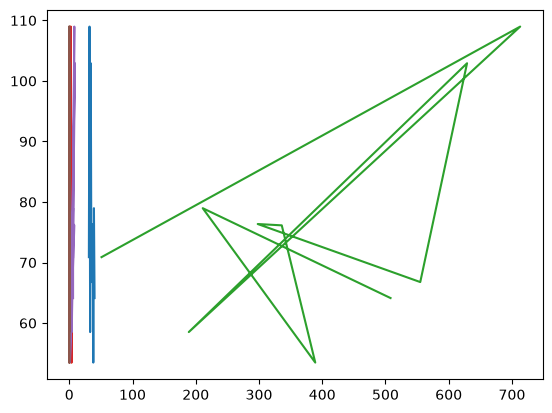

In [92]:
plt.plot(x_test,y_predicted_value)

## submission 

In [102]:
submission = pd.DataFrame({
    "Bug ID": df1["Bug ID"],
    "Predicted_value_for_test": y_predicted_value.ravel()
})

In [104]:
submission.to_csv("Final _kaggle_submission1.csv",index=False)